<a href="https://colab.research.google.com/github/Faizan-Mohammed-Yahya/DATA-QUALITY-ML-STUDY-REPO/blob/main/Data_quality_ml_research.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Phase 1: Data  Quality and Adult Income Prediction

This phase studies how commmon data-quality problems affect a logistic regression model that predicts whether annual income is above $50,000.


##Import libraries

This project uses Pandas for data work, Matplotlib for chart illustrations and scikit-learn for modelling.


In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    balanced_accuracy_score, confusion_matrix
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

RANDOM_SEEDS = [42,43,44] #TO ENSURE REPEATABILITY OF EXPERIMENTS
pd.set_option('display.max_columns', 30)

##2. Load the dataset
 The original adult.data file is read without editing it.


In [2]:

DATA_FILE = Path('adult.data')
NAMES_FILE = Path('adult.names') #as adult data has no headers we will asign
#column names

if not DATA_FILE.exists() or not NAMES_FILE.exists():
  from google.colab import files
  files.upload()

column_names = ['age', 'workclass','fnlwgt', 'education','education-num',
                'marital-status', 'occupation','relationship','race','sex',
                'capital-gain','capital-loss','hours-per-week','native-country'
                ,'income']

raw_data = pd.read_csv(
    DATA_FILE,
    names=column_names,
    skipinitialspace=True,
    dtype=str,
    keep_default_na=False
)

target_column = 'income'
positive_label = '>50K'
numeric_columns = ['age','fnlwgt','education-num','capital-gain',
                   'capital-loss', 'hours-per-week'
                   ]


allowed_categories = {}
for line in NAMES_FILE.read_text().splitlines():
  if ': ' in line:
    field,values = line.split(': ',1)
    if field in column_names and 'continuous' not in values:
      allowed_categories[field] = values.rstrip('.').split(', ')

valid_ranges = {
    'age': (17,120), 'fnlwgt': (2,None), 'education-num': (1,16),
    'capital-gain': (0,None), 'capital-loss': (0,None),
    'hours-per-week': (1,168)
}

In [3]:
raw_data.shape

(32561, 15)

##3. Prepare feature types

Question marks, blank strings, and NaN text are treated as missing. Numeric fields are then converted to numbers.

In [4]:
features = raw_data.drop(columns=target_column).copy()

for column in features.columns:
    missing_markers = features[column].str.strip().isin(["?", "NaN", ""])
    features.loc[missing_markers, column] = np.nan

for column in numeric_columns:
    features[column] = pd.to_numeric(features[column], errors="coerce")

categorical_columns = [
    column for column in features.columns if column not in numeric_columns
]

clean_labels = raw_data[target_column].str.strip()
target = (clean_labels == positive_label).astype(int)

features.dtypes.to_frame("data_type")

,data_type
age,int64
workclass,object
fnlwgt,int64
education,object
education-num,int64
marital-status,object
occupation,object
relationship,object
race,object
sex,object


##4. Missing values

Missing values are counted before any treatment is applied.

In [5]:

missing_profile = pd.DataFrame({
    'missing_count': features.isna().sum(
    ),
    'missing percent:': features.isna().mean().mul(100)
}).sort_values('missing_count', ascending = False)

missing_profile[missing_profile['missing_count']>0]

,missing_count,missing percent:
occupation,1843,5.660146
workclass,1836,5.638647
native-country,583,1.790486


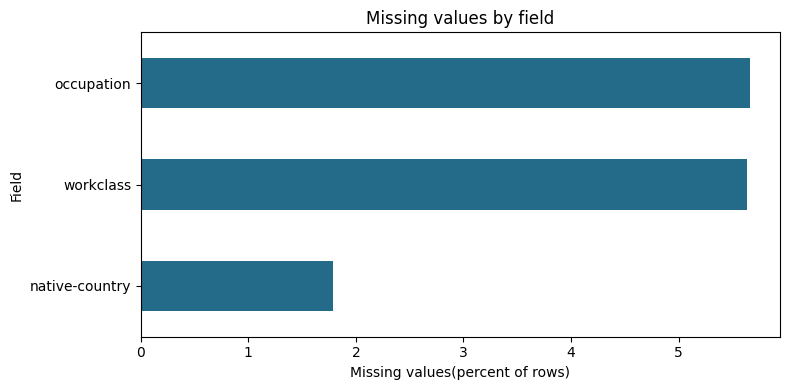

In [6]:

missing_profile[missing_profile['missing_count']>0].sort_values(
    'missing percent:'
).plot.barh(y='missing percent:', figsize=(8,4), color='#246b89', legend=False)

plt.title('Missing values by field')
plt.xlabel('Missing values(percent of rows)')
plt.ylabel('Field')
plt.tight_layout()
plt.tight_layout()
plt.savefig('phase1_missing_values.png', dpi=180)
plt.show()


##5. Duplicate records

Exact duplicates are checked using all features and the target together.


In [7]:

model_data=features.assign(target=target)
duplicate_count= int(model_data.duplicated().sum())
pd.DataFrame({
    "duplicate_rows": [duplicate_count],
    "percentage_of_dataset": [duplicate_count / len(model_data) * 100]
})


,duplicate_rows,percentage_of_dataset
0,24,0.073708


**Finding**: There are 24 extra exact duplicate rows. Their low prevalence means duplicate removal is expected to have only a small effect.

##6.Outliers

The IQR rule flags unusually high or low numerical values. A flag is not definitive proof that a value is wrong.

In [8]:
def calculate_iqr_bounds(data,columns):
  bounds = {}
  for column in columns:
    q1, q3 = data[column].quantile([0.25,0.75])
    iqr= q3-q1
    if pd.notna(iqr) and iqr > 0:
            bounds[column] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    return bounds


full_iqr_bounds = calculate_iqr_bounds(features, numeric_columns)
outlier_counts = {}
for column, (lower, upper) in full_iqr_bounds.items():
    outlier_counts[column] = int(
        ((features[column] < lower) | (features[column] > upper)).sum()
    )

pd.Series(outlier_counts, name="IQR_flag_count").sort_values(ascending=False).to_frame()


,IQR_flag_count
age,143


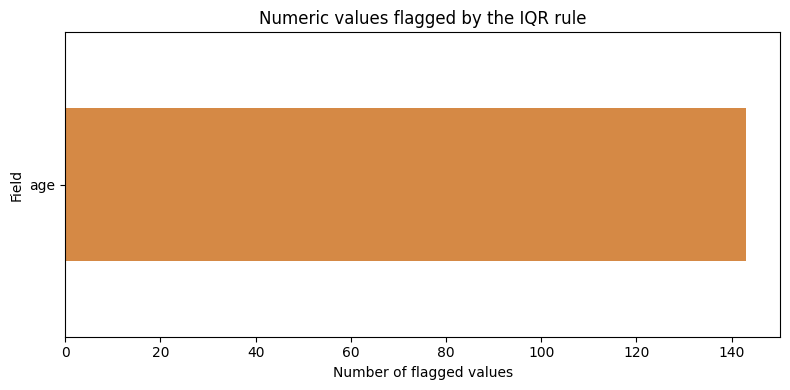

In [9]:
pd.Series(outlier_counts).sort_values().plot.barh(figsize=(8, 4), color="#d58945")
plt.title("Numeric values flagged by the IQR rule")
plt.xlabel("Number of flagged values")
plt.ylabel("Field")
plt.tight_layout()
plt.savefig("phase1_outlier_flags.png", dpi=180)
plt.show()

**Finding:** Some numeric tails are flagged, but plausible extreme values are kept in the baseline. E3 test cliiping seperately.

#7. Invalid or inconsistent values

Categories are compared with documented values. Numeric fields are checked against broad plausibility limits.

In [10]:

def standardise_values(data):
  cleaned = data.copy()
  for column, accepted_values in allowed_categories.items():
    cleaned[column] = cleaned[column].str.strip()
    cleaned[column] = cleaned[column].where(
        cleaned[column].isin(accepted_values),np.nan
    )

  for column,(lower,upper) in valid_ranges.items():
    invalid = cleaned[column]<lower
    if upper is not None:
      invalid = invalid | (cleaned[column]>upper)
    cleaned.loc[invalid,column] = np.nan
  return cleaned

standardised_features = standardise_values(features)
changed_by_rules = features.notna()&(
    features.ne(standardised_features)| standardised_features.isna()
)
changed_by_rules.sum().sort_values(ascending = False).to_frame('values_changed')




,values_changed
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


**Finding:** No invalid categories or range violations were found after  interpreting ? as missing. E4 is still retained as a valid no-effect test.

##8. Class distribution
both the count and percentage of each target class are examined

In [11]:

class_profile= pd.DataFrame({'count':target.value_counts().sort_index(),
                              'percent': target.value_counts(normalize = True).sort_index().mul(100)
                              })
class_profile.index = ['Negative class','Positive Class']
class_profile


,count,percent
Negative class,24720,75.919044
Positive Class,7841,24.080956


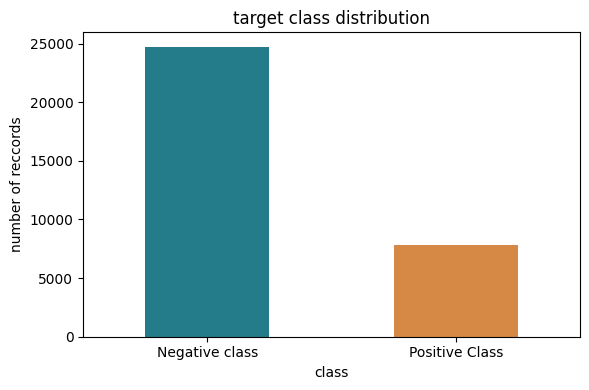

In [12]:
class_profile['count'].plot.bar(figsize=(6,4), color = ['#247b89', '#d58945'])
plt.title('target class distribution')
plt.xlabel('class')
plt.ylabel('number of reccords')
plt.xticks(rotation = 0)
plt.tight_layout()
plt.savefig('phase1_class_distribution.png',dpi =180)
plt.show()


**Finding:** Only 24.08% of records belong to the above-$50K class, so accuracy alone may hide weak minority-class performance.

## 9. Create a fair train/test split

Rows with the same canonical feature values are placed in only one split. This prevents duplicate information from leaking into the test set.


In [13]:
def make_grouped_split(data, labels, seed):
    canonical = standardise_values(data).fillna("__MISSING__").astype(str)
    group_ids = pd.util.hash_pandas_object(canonical, index=False).astype(str)

    group_labels = pd.DataFrame({"group": group_ids, "target": labels})
    group_labels = group_labels.groupby("group", sort=False)["target"].agg(
        lambda values: int(values.mean() >= 0.5)
    )

    train_groups, test_groups = train_test_split(
        group_labels.index,
        test_size=0.20,
        stratify=group_labels.values,
        random_state=seed
    )

    train_index = data.index[group_ids.isin(train_groups)]
    test_index = data.index[group_ids.isin(test_groups)]
    return train_index, test_index


train_index, test_index = make_grouped_split(features, target, seed=42)
print("Training rows:", len(train_index))
print("Testing rows:", len(test_index))

Training rows: 26051
Testing rows: 6510


## 10. Modelling method

Every experiment uses the same logistic regression approach. Only the named data-quality intervention changes.

In [14]:
experiment_names = {
    "E0": "Baseline placeholders",
    "E1": "Median and mode imputation",
    "E2": "Remove exact training duplicates",
    "E3": "Clip training IQR tails",
    "E4": "Standardise categories and invalid values",
    "E5": "Balanced class weights",
    "E6": "Combined E1, E2, E4 and E5"
}


def prepare_experiment(data, labels, train_rows, test_rows, experiment):
    x_train = data.loc[train_rows].copy()
    x_test = data.loc[test_rows].copy()
    y_train = labels.loc[train_rows].copy()
    y_test = labels.loc[test_rows].copy()
    removed_rows = 0
    changed_train = 0
    changed_test = 0

    if experiment in ["E2", "E6"]:
        keep = ~x_train.assign(target=y_train).duplicated()
        removed_rows = int((~keep).sum())
        x_train, y_train = x_train.loc[keep], y_train.loc[keep]

    if experiment in ["E4", "E6"]:
        clean_train = standardise_values(x_train)
        clean_test = standardise_values(x_test)
        changed_train = int((x_train.notna() & (x_train.ne(clean_train) | clean_train.isna())).sum().sum())
        changed_test = int((x_test.notna() & (x_test.ne(clean_test) | clean_test.isna())).sum().sum())
        x_train, x_test = clean_train, clean_test

    if experiment == "E3":
        training_bounds = calculate_iqr_bounds(x_train, numeric_columns)
        for column, (lower, upper) in training_bounds.items():
            changed_train += int(((x_train[column] < lower) | (x_train[column] > upper)).sum())
            changed_test += int(((x_test[column] < lower) | (x_test[column] > upper)).sum())
            x_train[column] = x_train[column].clip(lower, upper)
            x_test[column] = x_test[column].clip(lower, upper)

    return x_train, x_test, y_train, y_test, removed_rows, changed_train, changed_test

In [15]:
def build_model(experiment, seed):
    use_statistical_imputation = experiment in ["E1", "E6"]

    numeric_imputer = SimpleImputer(
        strategy="median" if use_statistical_imputation else "constant",
        fill_value=0,
        keep_empty_features=True
    )
    category_imputer = SimpleImputer(
        strategy="most_frequent" if use_statistical_imputation else "constant",
        fill_value="__MISSING__",
        keep_empty_features=True
    )

    preprocessing = ColumnTransformer([
        ("numeric", make_pipeline(numeric_imputer, StandardScaler()), numeric_columns),
        ("category", make_pipeline(category_imputer, OneHotEncoder(handle_unknown="ignore")), categorical_columns)
    ])

    classifier = LogisticRegression(
        C=1.0,
        solver="liblinear",
        max_iter=2000,
        tol=1e-6,
        class_weight="balanced" if experiment in ["E5", "E6"] else None,
        random_state=seed
    )
    return make_pipeline(preprocessing, classifier)


In [16]:
def evaluate_experiment(experiment, seed=42):
    train_rows, test_rows = make_grouped_split(features, target, seed)
    prepared = prepare_experiment(
        features, target, train_rows, test_rows, experiment
    )
    x_train, x_test, y_train, y_test, removed, changed_train, changed_test = prepared
    model = build_model(experiment, seed)

    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        with threadpool_limits(limits=1):
            model.fit(x_train, y_train)
            probability = model.predict_proba(x_test)[:, 1]

    prediction = (probability >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()

    return {
        "experiment": experiment,
        "intervention": experiment_names[experiment],
        "seed": seed,
        "train_rows": len(x_train), "test_rows": len(x_test),
        "removed_train_rows": removed,
        "rule_changed_train_cells": changed_train,
        "rule_changed_test_cells": changed_test,
        "accuracy": accuracy_score(y_test, prediction),
        "precision": precision_score(y_test, prediction, zero_division=0),
        "recall": recall_score(y_test, prediction, zero_division=0),
        "f1": f1_score(y_test, prediction, zero_division=0),
        "macro_f1": f1_score(y_test, prediction, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_test, prediction),
        "roc_auc": roc_auc_score(y_test, probability),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)
    }


def show_result(result):
    columns = ["experiment", "accuracy", "precision", "recall", "f1", "roc_auc"]
    return pd.DataFrame([result])[columns].round(6)

## 11. E0 — Original baseline

Missing values use simple placeholders. No quality intervention is applied.


In [17]:
main_results = []
e0_result = evaluate_experiment("E0")
main_results.append(e0_result)
show_result(e0_result)

,experiment,accuracy,precision,recall,f1,roc_auc
0,E0,0.851613,0.733333,0.603316,0.662001,0.90281


## 12. E1 — Missing-value treatment

Numeric gaps use the training median. Categorical gaps use the training mode.


In [18]:
e1_result = evaluate_experiment("E1")
main_results.append(e1_result)
show_result(e1_result)

,experiment,accuracy,precision,recall,f1,roc_auc
0,E1,0.850691,0.733909,0.596301,0.657987,0.90111


## 13. E2 — Duplicate treatment

Exact duplicates are removed from the training set only. The test set stays fixed.

In [19]:
e2_result = evaluate_experiment("E2")
main_results.append(e2_result)
show_result(e2_result)


,experiment,accuracy,precision,recall,f1,roc_auc
0,E2,0.85192,0.734472,0.603316,0.662465,0.90281


## 14. E3 — Outlier treatment

IQR limits learned from the training data are used to clip numeric values in both splits.


In [20]:
e3_result = evaluate_experiment("E3")
main_results.append(e3_result)
show_result(e3_result)


,experiment,accuracy,precision,recall,f1,roc_auc
0,E3,0.852227,0.734884,0.604592,0.663401,0.902924


## 15. E4 — Invalid and inconsistent values

Categories are standardised and values outside the documented rules become missing.


In [21]:
e4_result = evaluate_experiment("E4")
main_results.append(e4_result)
show_result(e4_result)


,experiment,accuracy,precision,recall,f1,roc_auc
0,E4,0.851613,0.733333,0.603316,0.662001,0.90281


## 16. E5 — Class-imbalance treatment

Balanced class weights give more importance to the smaller class during training.


In [22]:
e5_result = evaluate_experiment("E5")
main_results.append(e5_result)
show_result(e5_result)


,experiment,accuracy,precision,recall,f1,roc_auc
0,E5,0.799078,0.554484,0.84375,0.669196,0.902893


## 17. E6 — Combined selected pipeline

The final pipeline combines imputation, duplicate removal, category/range rules, and balanced class weights.


In [23]:
e6_result = evaluate_experiment("E6")
main_results.append(e6_result)
show_result(e6_result)

,experiment,accuracy,precision,recall,f1,roc_auc
0,E6,0.797696,0.552488,0.842474,0.66734,0.901234


## 18. Compare the experiments

Seed 42 is the main split used in the report.


In [24]:
results = pd.DataFrame(main_results)
baseline_f1 = results.loc[results["experiment"] == "E0", "f1"].iloc[0]
results["delta_f1"] = results["f1"] - baseline_f1

result_columns = [
    "experiment", "accuracy", "precision", "recall",
    "f1", "roc_auc", "delta_f1"
]
results[result_columns].round(6)

,experiment,accuracy,precision,recall,f1,roc_auc,delta_f1
0,E0,0.851613,0.733333,0.603316,0.662001,0.902810,0.000000
1,E1,0.850691,0.733909,0.596301,0.657987,0.901110,-0.004014
2,E2,0.851920,0.734472,0.603316,0.662465,0.902810,0.000464
3,E3,0.852227,0.734884,0.604592,0.663401,0.902924,0.001400
4,E4,0.851613,0.733333,0.603316,0.662001,0.902810,0.000000
5,E5,0.799078,0.554484,0.843750,0.669196,0.902893,0.007194
6,E6,0.797696,0.552488,0.842474,0.667340,0.901234,0.005339


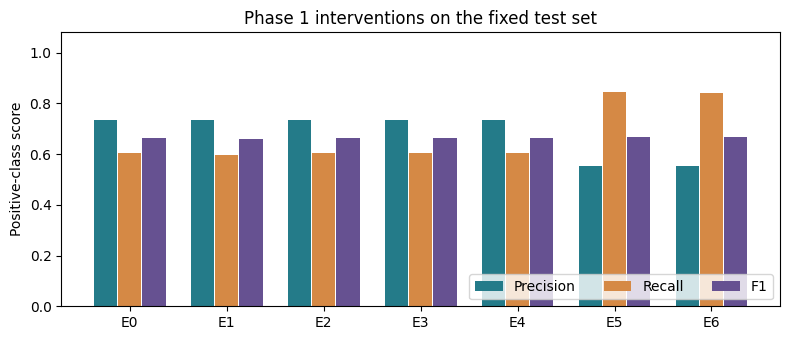

In [25]:
x_positions = np.arange(len(results))
fig, ax = plt.subplots(figsize=(8, 3.5))

for shift, metric, label, colour in [
    (-0.25, "precision", "Precision", "#247b89"),
    (0, "recall", "Recall", "#d58945"),
    (0.25, "f1", "F1", "#665191")
]:
    ax.bar(x_positions + shift, results[metric], width=0.24, label=label, color=colour)

ax.set_xticks(x_positions, results["experiment"])
ax.set_ylim(0, 1.08)
ax.set_ylabel("Positive-class score")
ax.set_title("Phase 1 interventions on the fixed test set")
ax.legend(ncol=3, loc="lower right")
fig.tight_layout()
fig.savefig("03_phase1_performance.png", dpi=180)
plt.show()

**Main result:** Class weighting (E5) produced the largest recall increase, from 0.6033 to 0.8438. Precision fell from 0.7333 to 0.5545, showing a clear trade-off.


## 19. Check sensitivity to the train/test split

Seeds 43 and 44 test whether the pattern is stable on two additional grouped splits.


In [26]:
all_results = main_results.copy()
for seed in [43, 44]:
    for experiment in experiment_names:
        all_results.append(evaluate_experiment(experiment, seed=seed))

all_seed_results = pd.DataFrame(all_results)
for metric in ["f1", "macro_f1", "accuracy", "recall", "roc_auc"]:
    baseline_by_seed = all_seed_results[
        all_seed_results["experiment"] == "E0"
    ].set_index("seed")[metric]
    all_seed_results["delta_" + metric] = (
        all_seed_results[metric] - all_seed_results["seed"].map(baseline_by_seed)
    )

all_seed_results.groupby("experiment")[["f1", "recall", "roc_auc"]].agg(["mean", "std"]).round(4)

f1          recall         roc_auc        
              mean     std    mean     std    mean     std
experiment                                                
E0          0.6630  0.0009  0.6040  0.0012  0.9073  0.0039
E1          0.6597  0.0026  0.5979  0.0042  0.9059  0.0042
E2          0.6630  0.0006  0.6038  0.0015  0.9073  0.0039
E3          0.6633  0.0008  0.6043  0.0021  0.9073  0.0038
E4          0.6630  0.0009  0.6040  0.0012  0.9073  0.0039
E5          0.6802  0.0100  0.8502  0.0094  0.9072  0.0037
E6          0.6785  0.0097  0.8519  0.0090  0.9059  0.0040

## 20. Save reproducible outputs

The result tables and profile files are generated directly from the calculations above.

In [27]:
field_profile = pd.DataFrame({
    "field": features.columns,
    "missing_count": features.isna().sum().values,
    "missing_percent": features.isna().mean().mul(100).values,
    "unique_nonmissing": features.nunique().values
})

profile_summary = {
    "rows": int(len(features)),
    "features": int(features.shape[1]),
    "missing_cells": int(features.isna().sum().sum()),
    "rows_with_missing": int(features.isna().any(axis=1).sum()),
    "exact_duplicate_extras": duplicate_count,
    "positive_count": int(target.sum()),
    "negative_count": int((1 - target).sum()),
    "positive_percent": float(target.mean() * 100),
    "random_seeds": RANDOM_SEEDS
}

results.to_csv("phase1_results.csv", index=False)
all_seed_results.to_csv("phase1_all_seeds.csv", index=False)
field_profile.to_csv("phase1_field_profile.csv", index=False)
Path("phase1_profile.json").write_text(json.dumps(profile_summary, indent=2))

print("Saved result tables, profile files, and chart images.")

Saved result tables, profile files, and chart images.


## Conclusion

The experiments show association, not proof of causation. A cleaning step can improve one metric, reduce another, or make almost no difference. Its value depends on the dataset and the prediction goal.